# spxhack: снимки SPHEREx во времени прямо в Python

Библиотека делает то же, что сайт, но результат — массивы numpy, с которыми можно работать дальше.
Ниже: WISE 0855 (самый холодный известный коричневый карлик) и звезда Барнарда. Измеряем их положение в каждой
эпохе SPHEREx и получаем **собственное движение по самим снимкам**, сравнивая с каталогом.

Данные: NASA SPHEREx через NASA/IPAC IRSA. Первый запуск качает вырезки (несколько минут), потом они в кэше.

In [1]:
import sys
sys.path.insert(0, "../src")          # ноутбук лежит в examples/
import numpy as np
import matplotlib.pyplot as plt
import spxhack as spx
from astropy import log
log.setLevel("WARNING")              # без INFO-сообщений astropy о заголовках
spx.__version__

'0.1.0'

## 1. WISE 0855: данные и «мигалка»

WISE 0855 почти не светит короче 4 мкм, поэтому берём детектор 6 (4.4–5.0 мкм).

In [2]:
t = spx.target("wise0855")
exps = spx.fetch(t, det=6, fov=3)       # поиск в IRSA + вырезки
st = spx.stack(exps, t, fov=3)           # эпохи -> сложенные кадры на одной сетке, север вверху
st

Stack('WISE 0855-0714', 4 epochs 2025-05-05..2026-04-28, 29x29 px)

In [3]:
spx.show(st, track=spx.track(st))      # зелёный круг — прогноз по каталогу, жёлтый — измерено

## 2. Всё — numpy

In [4]:
cube = np.asarray(st)                    # (эпохи, y, x), MJy/sr, NaN = нет данных
print(cube.shape, st.dates, np.round(st.wave, 2))
d = spx.diff(st)                         # разностные кадры в сигмах
v = d[np.isfinite(d)]
print(d.shape, "шум разности (MAD) ≈", round(float(1.4826 * np.median(np.abs(v - np.median(v)))), 2), "σ")

(4, 29, 29) ['2025-05-05', '2025-11-12', '2025-12-12', '2026-04-28'] [4.94 4.69 4.69 4.71]
(4, 29, 29) шум разности (MAD) ≈ 1.0 σ


## 3. Положение в каждой эпохе и собственное движение

In [5]:
tr = spx.track(st)
for r in tr:
    print(r["date"], f'{r["wave_um"]:.2f} мкм', r["status"], r["quality"],
          None if r["offset_px"] is None else f'отклонение от прогноза {r["offset_px"]:.2f} px')
tr.to_numpy()[:, :5]                     # mjd, x, y, err_x, err_y

2025-05-05 4.94 мкм none None None
2025-11-12 4.69 мкм ok good отклонение от прогноза 0.32 px
2025-12-12 4.69 мкм ok good отклонение от прогноза 0.12 px
2026-04-28 4.71 мкм ok good отклонение от прогноза 0.31 px


array([[6.08007460e+04,            nan,            nan,            nan,
                   nan],
       [6.09915958e+04, 1.40476251e+01, 1.42050117e+01, 6.04280450e-02,
        6.21980511e-02],
       [6.10215551e+04, 1.40689259e+01, 1.39902122e+01, 7.53008903e-02,
        7.50394031e-02],
       [6.11589392e+04, 1.47806185e+01, 1.42831858e+01, 8.30634793e-02,
        8.64449004e-02]])

In [6]:
pm = spx.fit_motion(tr)
print(pm)
print("отличие от каталога, σ:", np.round(pm.difference_sigma, 2), " χ²_red:", round(pm.chi2_red, 2))

Motion(pm = [-8.30 ± 2.49, +1.14 ± 2.49] arcsec/yr, 3 epochs over 0.46 yr; catalogue [-8.12, +0.67])
отличие от каталога, σ: [-0.07  0.19]  χ²_red: 3.26


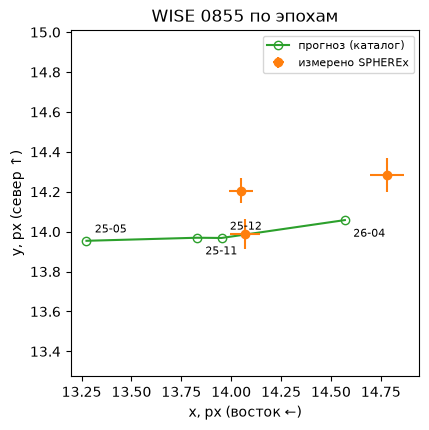

In [7]:
a = tr.to_numpy()
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot(a[:, 8], a[:, 9], "o-", mfc="none", color="tab:green", label="прогноз (каталог)")
ax.errorbar(a[:, 1], a[:, 2], xerr=a[:, 3], yerr=a[:, 4], fmt="o", color="tab:orange", label="измерено SPHEREx")
for i, r in enumerate(tr):
    ax.annotate(r["date"][2:7], (a[i, 8], a[i, 9]), textcoords="offset points", xytext=(6, -12 if i % 2 else 6), fontsize=8)
ax.set_xlabel("x, px (восток ←)"); ax.set_ylabel("y, px (север ↑)"); ax.set_aspect("equal", adjustable="datalim"); ax.legend(fontsize=8)
ax.set_title("WISE 0855 по эпохам");

## 4. Звезда Барнарда

Самое быстрое собственное движение среди звёзд, ~10.4″/год на север. Ядро насыщено: центр мерится по крыльям (флаг `saturated_core`).

In [8]:
tb = spx.target("barnard")
sb = spx.stack(spx.fetch(tb, det=3, fov=3), tb, fov=3)
trb = spx.track(sb)
print(spx.fit_motion(trb))
spx.show(sb, track=trb)

Motion(pm = [+0.49 ± 2.06, +9.03 ± 2.06] arcsec/yr, 4 epochs over 0.99 yr; catalogue [-0.80, +10.36])


## 5. Спектр и файлы для других программ

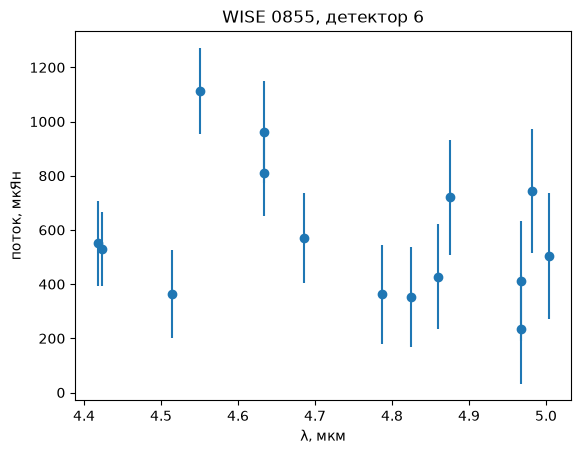

In [9]:
sp = spx.spectrum(exps, t)               # фотометрия в точке цели на каждой длине волны детектора 6
w, f, e = sp.to_numpy().T                # только надёжные точки
plt.errorbar(w, f, e, fmt="o"); plt.xlabel("λ, мкм"); plt.ylabel("поток, мкЯн"); plt.title("WISE 0855, детектор 6");

In [10]:
spx.to_fits(st, "wise0855_cube.fits", overwrite=True)   # куб + WCS: открывается в DS9 / Aladin
spx.save(st, "wise0855_out")["frames"][0]["urls"]       # PNG / GIF как на сайте

{'coadd': './f0.png', 'diff': './f0_diff.png', 'flags': './f0_flags.png'}

## Что важно знать

* Пиксели — numpy: `[x, y]` от 0, ось y на север, восток слева.
* У каждого измерения есть `quality`, `flags` и ошибка; `spx.METHODS` описывает методы и их ограничения.
* Ошибка центра шумовая; при χ²_red > 1 ошибки движения масштабируются на √χ²_red.
* Не сделано: PSF-фиттинг, деблендинг, нейросети.